# 03 - Loss Functions & Optimizers (SGD, Momentum, Adam)
**Learning goals:** MSE, MAE, Binary/Categorical cross-entropy; gradient descent variants; Adam update rule; compare them visually.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
np.random.seed(0)

## 1. Loss functions
A **loss** measures how wrong predictions are; training = minimizing it.

| Loss | Formula | Task |
|---|---|---|
| MSE | $\frac1n\sum (y-\hat y)^2$ | regression |
| MAE | $\frac1n\sum |y-\hat y|$ | regression (robust to outliers) |
| Binary cross-entropy | $-\frac1n\sum [y\log \hat y+(1-y)\log(1-\hat y)]$ | binary classification |
| Categorical cross-entropy | $-\frac1n\sum_i\sum_k y_{ik}\log \hat y_{ik}$ | multi-class |

In [2]:
def mse(y, p): return np.mean((y-p)**2)
def mae(y, p): return np.mean(np.abs(y-p))
def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1-eps); return -np.mean(y*np.log(p)+(1-y)*np.log(1-p))
def cce(Y, P, eps=1e-12):
    P = np.clip(P, eps, 1); return -np.mean(np.sum(Y*np.log(P), axis=1))

y_true = np.array([3.0, -0.5, 2.0, 7.0]); y_pred = np.array([2.5, 0.0, 2.0, 8.0])
print('MSE', mse(y_true, y_pred), '| MAE', mae(y_true, y_pred))
print('BCE', bce(np.array([1,0,1,1]), np.array([.9,.2,.7,.4])))
print('CCE', cce(np.array([[1,0,0],[0,1,0]]), np.array([[.8,.1,.1],[.2,.6,.2]])))

MSE 0.375 | MAE 0.5
BCE 0.4003674356962309
CCE 0.3669845875401002


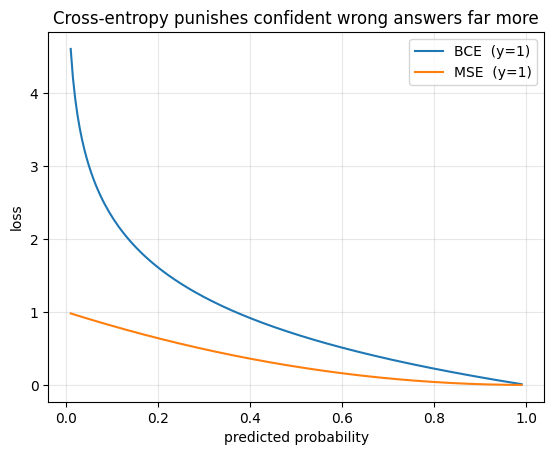

In [3]:
# Intuition: for a true label of 1, how does each loss react to the predicted probability?
p = np.linspace(0.01, 0.99, 200)
plt.plot(p, -np.log(p), label='BCE  (y=1)'); plt.plot(p, (1-p)**2, label='MSE  (y=1)')
plt.xlabel('predicted probability'); plt.ylabel('loss'); plt.legend(); plt.grid(alpha=.3)
plt.title('Cross-entropy punishes confident wrong answers far more'); plt.show()

## 2. Gradient descent family
$\theta \leftarrow \theta - \eta \nabla_\theta L$

- **Batch GD:** all data per step (stable, slow)
- **SGD:** one sample per step (noisy, fast)
- **Mini-batch SGD:** small batches (the practical default)
- **Momentum:** $v \leftarrow \beta v + \nabla L$, $\theta \leftarrow \theta - \eta v$ (smooths noise)
- **Adam:** momentum + adaptive per-parameter learning rate

**Adam:**
$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t$, $v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$,
$\hat m_t=\frac{m_t}{1-\beta_1^t}$, $\hat v_t=\frac{v_t}{1-\beta_2^t}$, $\theta \leftarrow \theta-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$

In [4]:
class SGD:
    def __init__(self, lr=0.01): self.lr = lr
    def step(self, p, g): return p - self.lr*g

class Momentum:
    def __init__(self, lr=0.01, beta=0.9): self.lr, self.beta, self.v = lr, beta, 0
    def step(self, p, g):
        self.v = self.beta*self.v + g
        return p - self.lr*self.v

class Adam:
    def __init__(self, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.m, self.v, self.t = lr, b1, b2, eps, 0, 0, 0
    def step(self, p, g):
        self.t += 1
        self.m = self.b1*self.m + (1-self.b1)*g
        self.v = self.b2*self.v + (1-self.b2)*g**2
        mh, vh = self.m/(1-self.b1**self.t), self.v/(1-self.b2**self.t)
        return p - self.lr*mh/(np.sqrt(vh)+self.eps)

## 3. Visual comparison on a 2-D "valley" function
$f(x,y)=0.1x^2+2y^2$ - steep in y, shallow in x. Plain SGD zig-zags; Adam adapts.

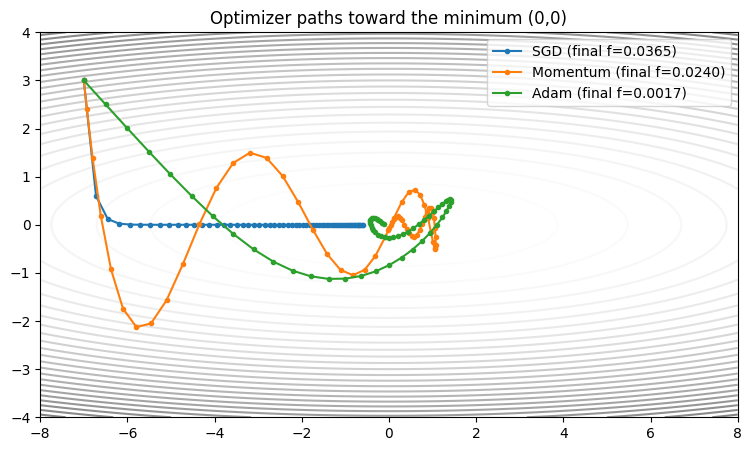

In [5]:
f    = lambda x, y: 0.1*x**2 + 2*y**2
grad = lambda x, y: np.array([0.2*x, 4*y])

start = np.array([-7.0, 3.0]); paths = {}
for name, opt in {'SGD': SGD(0.2), 'Momentum': Momentum(0.05, 0.9), 'Adam': Adam(0.5)}.items():
    p, path = start.copy(), [start.copy()]
    for _ in range(60):
        p = opt.step(p, grad(*p)); path.append(p.copy())
    paths[name] = np.array(path)

xx, yy = np.meshgrid(np.linspace(-8,8,200), np.linspace(-4,4,200))
plt.figure(figsize=(9,5)); plt.contour(xx, yy, f(xx,yy), 25, cmap='Greys', alpha=.5)
for n, pa in paths.items(): plt.plot(pa[:,0], pa[:,1], 'o-', ms=3, label=f'{n} (final f={f(*pa[-1]):.4f})')
plt.legend(); plt.title('Optimizer paths toward the minimum (0,0)'); plt.show()

## 4. Optimizers on a real task: logistic regression (breast cancer data)

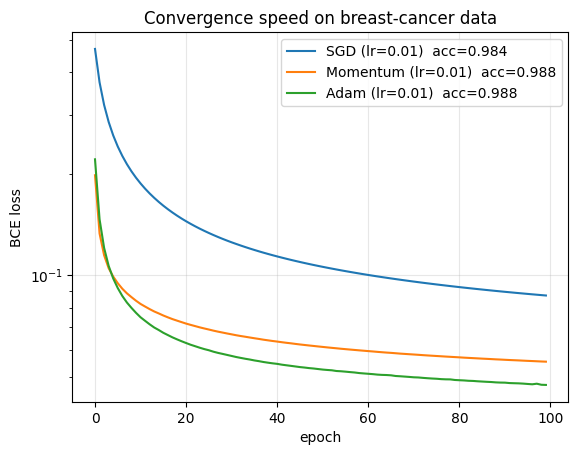

In [6]:
df = pd.read_csv('../data/breast_cancer.csv')
X = StandardScaler().fit_transform(df.drop(columns='target')); y = df['target'].values
sig = lambda z: 1/(1+np.exp(-z))

def train(opt, epochs=100, batch=32, seed=0):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1]); b = np.zeros(1); hist = []
    ow, ob = opt(), opt()
    for _ in range(epochs):
        idx = rng.permutation(len(X))
        for s in range(0, len(X), batch):
            i = idx[s:s+batch]; err = sig(X[i]@w+b) - y[i]
            w = ow.step(w, X[i].T@err/len(i)); b = ob.step(b, np.array([err.mean()]))
        hist.append(bce(y, sig(X@w+b)))
    return hist, ((sig(X@w+b)>=.5)==y).mean()

res = {'SGD (lr=0.01)': lambda: SGD(0.01), 'Momentum (lr=0.01)': lambda: Momentum(0.01),
       'Adam (lr=0.01)': lambda: Adam(0.01)}
for n, o in res.items():
    h, acc = train(o); plt.plot(h, label=f'{n}  acc={acc:.3f}')
plt.xlabel('epoch'); plt.ylabel('BCE loss'); plt.yscale('log'); plt.legend(); plt.grid(alpha=.3)
plt.title('Convergence speed on breast-cancer data'); plt.show()

## 5. Learning-rate sensitivity

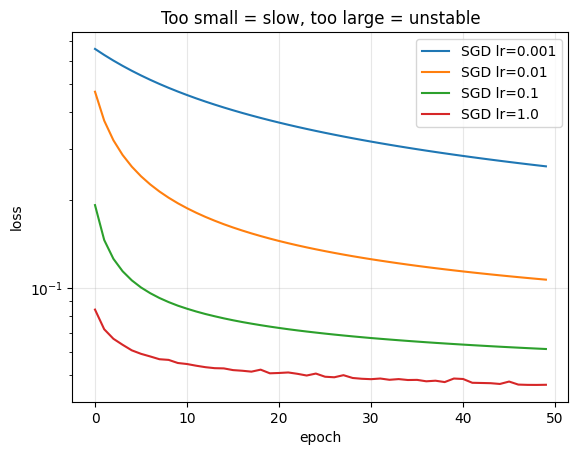

In [7]:
for lr in [0.001, 0.01, 0.1, 1.0]:
    h, acc = train(lambda: SGD(lr), epochs=50)
    plt.plot(h, label=f'SGD lr={lr}')
plt.yscale('log'); plt.legend(); plt.xlabel('epoch'); plt.ylabel('loss'); plt.grid(alpha=.3)
plt.title('Too small = slow, too large = unstable'); plt.show()

## 6. Summary
| Optimizer | Pros | Cons |
|---|---|---|
| SGD | simple, generalizes well | sensitive to learning rate, slow in ravines |
| Momentum | faster, smoother | one more hyper-parameter |
| Adam | fast, robust defaults (lr=1e-3) | sometimes generalizes slightly worse than tuned SGD |

## 7. Practice tasks
1. Add **RMSProp** and compare with Adam.
2. Try batch sizes 1, 32, 569 (full batch) and compare convergence.
3. Implement learning-rate decay and show its effect.